# 02 — Oscillator networks scale: running Un-0's 16,384-oscillator ImageNet model locally

**Tutorial for Fig 7, panel B ("振荡网络可扩展" — oscillator networks scale).**

Panel B of Fig 7 makes one claim: the coupled-oscillator architecture is not only a
toy — it scales to a large, practically useful generative model. To show this we downloaded the
**released checkpoint of Un-0's ImageNet-64 model** (16,384 coupled Kuramoto oscillators,
[HuggingFace `un-ai/Un-0`](https://huggingface.co/un-ai/Un-0), MIT licence), ran it locally, and
measured what its oscillator dynamics actually do during generation.

This notebook documents **everything** done with the Un-0 data — including the artefacts that did
*not* make it into Fig 7:

| Artefact | Made by | In Fig 7? |
|---|---|---|
| `results/un0_samples.pt`, `results/un0_grid.png` — uncurated class-conditional samples (15 classes × 4) | `experiments/un0_samples.py` | **No** — shown here |
| `results/un0_dynamics.pt` — full oscillator state at every integration step (10 classes × 40 samples) | `experiments/un0_dynamics.py` | panel B reads this |
| `results/un0_dynamics.png` — 3-panel summary (image strip, PCA trajectories, decoding curve) | `experiments/un0_dynamics.py` | parts reused in panel B |
| `results/un0_subspace.png` — standalone, larger rendering of panel B | `experiments/make_overview_figure.py` | panel B is a smaller crop of this |

Everything below runs on CPU in about a minute and does **not** need the 3.9 GB checkpoint — it only
loads the saved results.

## Goal

**Question:** does the coupled-oscillator computation scale beyond hand-built toy problems — and what
do the oscillator dynamics *do* inside a large trained model?

**Why it matters:** panels A and C of Fig 7 use small models we built ourselves
(72 oscillators; ~58k parameters). One could reasonably ask whether any of this survives at
realistic scale. Un-0's ImageNet-64 model answers that: 16,384 oscillators with learned couplings
(~285M parameters in the dynamics), trained by someone else, generating recognisable images. Our
contribution here is the *measurement*: we keep the full oscillator state at every integration step
and ask (following Un-0's own blog figures 0, 5b and 6, recomputed locally):

- **(a)** what does the decoder see at each step? → decode intermediate states into images;
- **(b)** how does the oscillator state move? → PCA of the readout features;
- **(c)** when does the state carry the class? → nearest-centroid class decoding at each step.

## Method

**The model (Un-0, not ours).** An image is generated by integrating **16,385 coupled Kuramoto
oscillators** for 10 Euler steps (t = 0 → 1), starting from **random phases**, with a
**class-specific one-way drive**; a learned decoder then maps the final phases to pixels
(`experiments/un0_dynamics.py` docstring; the model itself comes from the released checkpoint).

**What we ran locally** (both scripts need `checkpoints/imagenet64_n16384.pt`, 3.9 GB, git-ignored;
download command in the `un0_samples.py` docstring and in the last section of this notebook):

1. `experiments/un0_samples.py` — **uncurated** class-conditional samples: fixed seed 0, the first 4
   samples of each of 15 chosen ImageNet classes are kept (no cherry-picking). → `results/un0_samples.pt`,
   `results/un0_grid.png`.
2. `experiments/un0_dynamics.py` — integrates the dynamics for 10 classes × 40 samples, keeping the
   **full state at every step**, then:
   - decodes one sample per shown class at every step (the image strip);
   - fits PCA (10 components) on the readout features at t = 1, using **half the samples of each class
     as a train split**, and projects every step of every sample onto the first 3 PCs;
   - builds class centroids in the 10-PC space from the train half and reports **nearest-centroid
     decoding accuracy on the held-out half** at every step (chance = 1/10).

Two practical notes: `torch.compile` is disabled (`TORCHDYNAMO_DISABLE=1`) because it needs Triton,
which is not available on Windows — results are unchanged; and the checkpoint was saved from
`torch.compile`'d modules, so the scripts strip the `_orig_mod.` prefix from the state dict.

In [1]:
%matplotlib inline
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = Path('..') if Path('.').resolve().name == 'notebooks' else Path('.')  # works from repo root or notebooks/
RES = ROOT / 'results'

d = torch.load(RES / 'un0_dynamics.pt', map_location='cpu', weights_only=False)
print('keys and shapes in results/un0_dynamics.pt:')
for k, v in d.items():
    if isinstance(v, torch.Tensor):
        print(f'  {k:22s} tensor {tuple(v.shape)} {v.dtype}')
    elif isinstance(v, dict):
        print(f'  {k:22s} dict   {{{len(v)} entries}}')
    else:
        print(f'  {k:22s} {type(v).__name__} = {v if not isinstance(v, list) else [round(x, 3) for x in v]}')

print()
print(f"{d['n_oscillators']:,} oscillators (+1 class-conditioning oscillator), "
      f"{len(d['names'])} classes x {d['per_class']} samples, {len(d['time'])} time points "
      f"(t = {d['time'][0]} .. {d['time'][-1]})")
print('explained variance of PC 1-3 (fit at t=1):', [round(x, 4) for x in d['explained_var_pc123']])

keys and shapes in results/un0_dynamics.pt:
  time                   list = [0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0]
  proj                   tensor (11, 400, 3) torch.float32
  labels                 tensor (400,) torch.int64
  names                  dict   {10 entries}
  strip                  dict   {3 entries}
  decoding_acc           list = [0.105, 0.365, 0.515, 0.61, 0.69, 0.79, 0.87, 0.915, 0.925, 0.935, 0.97]
  chance                 float = 0.1
  explained_var_pc123    list = [0.021, 0.02, 0.02]
  per_class              int = 40
  n_oscillators          int = 16384

16,384 oscillators (+1 class-conditioning oscillator), 10 classes x 40 samples, 11 time points (t = 0.0 .. 1.0)
explained variance of PC 1-3 (fit at t=1): [0.0206, 0.0201, 0.0198]


`proj` is the PCA projection of every sample at every step — shape (time, samples, 3). `strip` holds
the decoded image of one sample per shown class (flamingo, monarch, volcano) at every step.
`decoding_acc` is the held-out nearest-centroid class accuracy per step.

## Result 1 — images emerge as the oscillators evolve

Decoding the intermediate oscillator states at each of the 11 saved time points (one sample per class,
exactly the strip stored in `un0_dynamics.pt`; this became the left part of the 3-panel
`results/un0_dynamics.png`, after Un-0's blog Fig 0):

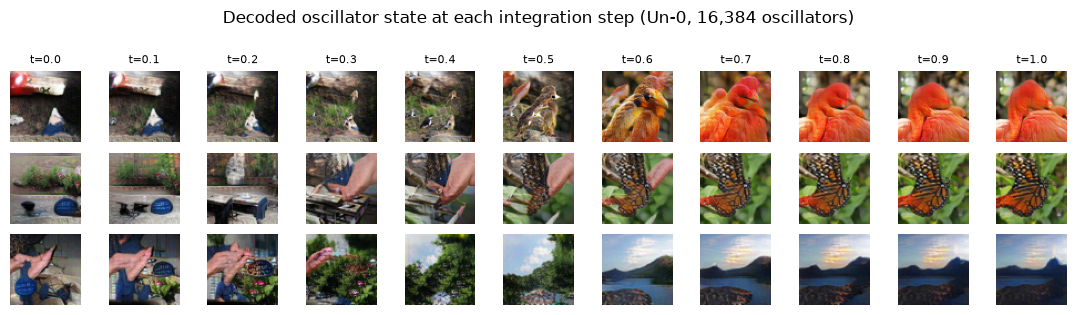

In [2]:
time = np.array(d['time'])
rows = list(d['strip'])                      # classes 130 flamingo, 323 monarch, 980 volcano
fig, axes = plt.subplots(len(rows), len(time), figsize=(11, 3.1))
for r, c in enumerate(rows):
    for k in range(len(time)):
        ax = axes[r, k]
        ax.imshow(d['strip'][c][k].permute(1, 2, 0).numpy())
        ax.set_axis_off()
        if k == 0:
            ax.set_ylabel(d['names'][c], rotation=0, ha='right', va='center', fontsize=9)
        if r == 0:
            ax.set_title(f't={time[k]:.1f}', fontsize=8)
fig.suptitle('Decoded oscillator state at each integration step (Un-0, 16,384 oscillators)', y=1.0)
fig.tight_layout()
plt.show()

From random phases (t = 0, noise) the class-specific drive pulls the state into a recognisable image
by t ≈ 0.5, and the remaining steps refine it.

## Result 2 — panel B reproduced: random phases → class clusters

This is the scatter plot that became **panel B of Fig 7** (`panel_subspace` in
`experiments/make_overview_figure.py`, reused by `experiments/make_final_figure.py`): each point is
one held-out-or-train sample's PCA projection; bold lines are class-mean trajectories over the 10
steps, thin lines the first 4 samples per class, and the two **dashed** trajectories (flamingo,
monarch) are the ones whose final images are shown as thumbnails.

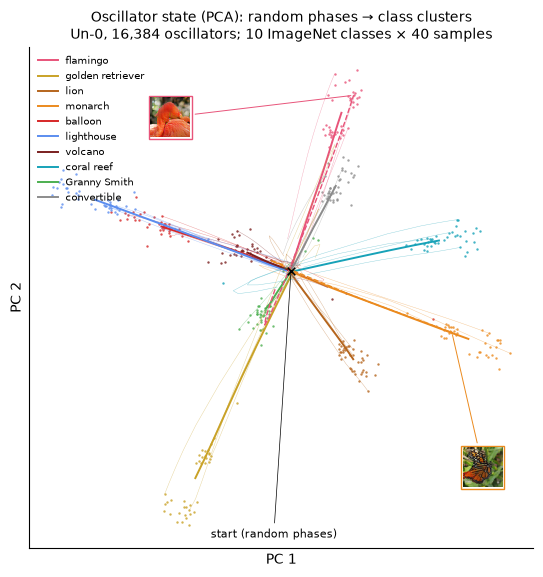

In [3]:
from matplotlib.offsetbox import AnnotationBbox, OffsetImage

# same class colours as experiments/un0_dynamics.py / make_overview_figure.py
COLORS = ['#e8547a', '#c9a227', '#b5651d', '#eb8a1e', '#d62728', '#5b8def', '#7a1f1f', '#17a2b8',
          '#4caf50', '#8c8c8c']
proj, lab = d['proj'].numpy(), d['labels'].numpy()
names = list(d['names'])

fig, ax = plt.subplots(figsize=(6.5, 6.5))
for i, c in enumerate(names):
    m = lab == c
    for s in np.flatnonzero(m)[:4]:
        ax.plot(proj[:, s, 0], proj[:, s, 1], color=COLORS[i], lw=0.3, alpha=0.5)
    mu = proj[:, m].mean(1)
    ax.plot(mu[:, 0], mu[:, 1], color=COLORS[i], lw=1.4, label=d['names'][c])
    ax.scatter(proj[-1, m, 0], proj[-1, m, 1], s=3, color=COLORS[i], lw=0, alpha=0.8)

x0, y0 = proj[0, :, 0].mean(), proj[0, :, 1].mean()
ax.scatter(x0, y0, s=30, color='k', marker='x', lw=1.2, zorder=5)
ax.annotate('start (random phases)', (x0, y0), xytext=(0.36, 0.02), textcoords='axes fraction',
            fontsize=8, arrowprops={'arrowstyle': '-', 'lw': 0.5, 'color': 'k'})

# the two highlighted trajectories, with the images they end in (as in panel B of Fig 7)
boxes = {130: (0.28, 0.86), 323: (0.9, 0.16)}
for c in (130, 323):
    i = names.index(c)
    s = int(np.flatnonzero(lab == c)[0])               # the sample decoded in the strip above
    ax.plot(proj[:, s, 0], proj[:, s, 1], color=COLORS[i], lw=1.0, ls='--')
    img = d['strip'][c][-1].permute(1, 2, 0).numpy()
    ab = AnnotationBbox(OffsetImage(img, zoom=0.45), (proj[-1, s, 0], proj[-1, s, 1]),
                        xybox=boxes[c], boxcoords='axes fraction', pad=0.1,
                        bboxprops={'edgecolor': COLORS[i], 'lw': 1.0},
                        arrowprops={'arrowstyle': '-', 'color': COLORS[i], 'lw': 0.7})
    ax.add_artist(ab)

ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel('PC 1'); ax.set_ylabel('PC 2')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
ax.legend(fontsize=7, loc='upper left', frameon=False)
ax.set_title('Oscillator state (PCA): random phases → class clusters\n'
             'Un-0, 16,384 oscillators; 10 ImageNet classes × 40 samples', fontsize=10)
plt.show()

All 400 samples start at the same place (the cross — random phases carry no class information) and
separate into class clusters as the dynamics proceed. Two honest caveats about this view: the first
three PCs carry only ~2% of the variance each (the state is genuinely high-dimensional, so this is a
low-dimensional *glimpse*, not a summary), and the PCA basis is fit at t = 1 on the train half —
early steps are projections onto that basis, which is why the trajectories fan out from one point.

## Result 3 — when does the state carry the class?

Nearest-centroid decoding in the 10-PC space: centroids from the train half of each class, accuracy
scored on the **held-out half** (200 samples, chance = 10%).

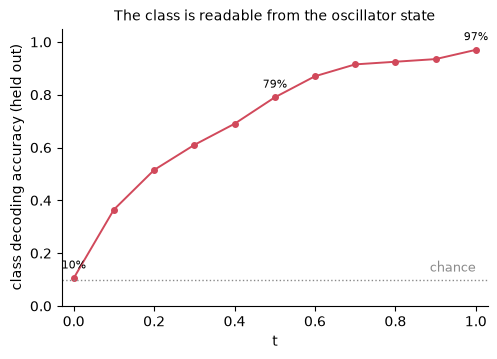

decoding accuracy by step: [0.1, 0.37, 0.51, 0.61, 0.69, 0.79, 0.87, 0.92, 0.93, 0.94, 0.97]


In [4]:
fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.plot(time, d['decoding_acc'], 'o-', color='#d1495b', ms=4, lw=1.4)
ax.axhline(d['chance'], color='#8a8a8a', ls=':', lw=1)
ax.text(time[-1], d['chance'] + 0.03, 'chance', ha='right', fontsize=9, color='#8a8a8a')
for t, a in [(time[0], d['decoding_acc'][0]), (time[5], d['decoding_acc'][5]), (time[-1], d['decoding_acc'][-1])]:
    ax.annotate(f'{a:.0%}', (t, a), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8)
ax.set_ylim(0, 1.05); ax.set_xlim(-0.03, 1.03)
ax.set_xlabel('t'); ax.set_ylabel('class decoding accuracy (held out)')
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
ax.set_title('The class is readable from the oscillator state', fontsize=10)
plt.show()

print('decoding accuracy by step:', [round(a, 2) for a in d['decoding_acc']])

Accuracy rises monotonically from chance (10%) to **97%** at t = 1 — the number quoted in the
figure caption. Already at t = 0.5 the state is 79% decodable, matching the image strip above:
the class structure is in place halfway through the integration and the later steps refine it.

## Beyond the figure — uncurated samples

Fig 7 contains no sample grid. For completeness we also generated **uncurated**
class-conditional samples with `experiments/un0_samples.py`: fixed seed 0, the *first* 4 samples of
each of 15 classes, no selection. This is the honest version of "the model generates recognisable
images" — quality varies, and some samples are ambiguous, which is expected for an uncurated 64×64
class-conditional model. The grid (columns = classes, rows = the 4 samples) is saved as
`results/un0_grid.png`:

un0_samples.pt: (60, 3, 64, 64) images, seed 0, 16,384 oscillators, dynamics params 285M, decoder params 38M


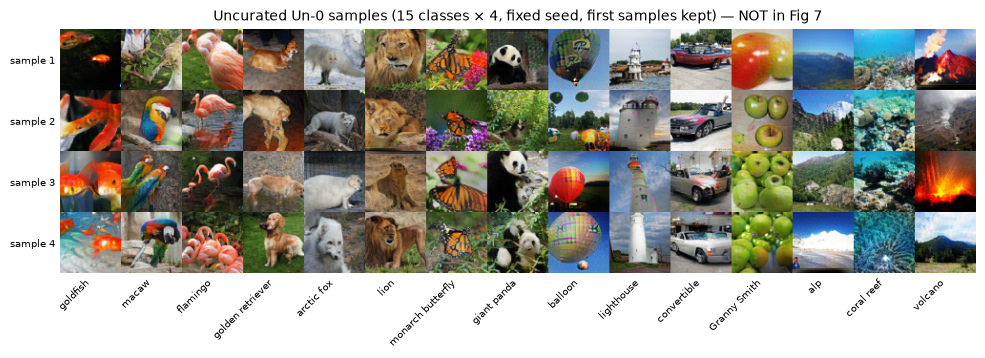

In [5]:
s = torch.load(RES / 'un0_samples.pt', map_location='cpu', weights_only=False)
print(f"un0_samples.pt: {tuple(s['images'].shape)} images, seed {s['seed']}, "
      f"{s['n_oscillators']:,} oscillators, "
      f"dynamics params {s['dynamics_params']/1e6:.0f}M, decoder params {s['decoder_params']/1e6:.0f}M")

grid = plt.imread(RES / 'un0_grid.png')
fig, ax = plt.subplots(figsize=(13, 3.6))
ax.imshow(grid)
k = s['per_class']
ax.set_xticks([(i + 0.5) * 64 for i in range(len(s['names']))])
ax.set_xticklabels(list(s['names'].values()), rotation=45, ha='right', fontsize=7)
ax.set_yticks([(i + 0.5) * 64 for i in range(k)])
ax.set_yticklabels([f'sample {i + 1}' for i in range(k)], fontsize=7)
ax.tick_params(length=0)
for sp in ax.spines.values():
    sp.set_visible(False)
ax.set_title('Uncurated Un-0 samples (15 classes × 4, fixed seed, first samples kept) — NOT in Fig 7',
             fontsize=10)
fig.tight_layout()
plt.show()

## Beyond the figure — the standalone panel B (`un0_subspace.png`)

`experiments/make_overview_figure.py` also saves panel B on its own, at a larger size than it appears
in Fig 7: `results/un0_subspace.png` (and `_zh` for Chinese labels). The *extra* it
contains relative to panel B in Fig 7 is only presentational — a larger rendering with the full
annotation ("random phases → class clusters", decoding 10% → 97% in the note) and the two highlighted
trajectories (flamingo, monarch) with their endpoint images; the underlying numbers are the same
`results/un0_dynamics.pt` used above. The sibling artefact `results/un0_dynamics.png` is the full
3-panel measurement summary (image strip + PCA trajectories + decoding curve) whose pieces the
Fig 7 panel was assembled from.

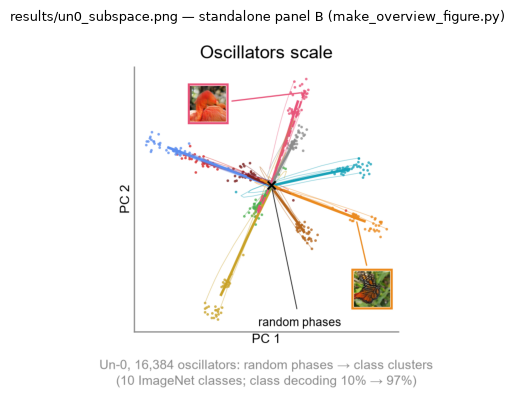

In [6]:
img = plt.imread(RES / 'un0_subspace.png')
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.imshow(img)
ax.set_axis_off()
ax.set_title('results/un0_subspace.png — standalone panel B (make_overview_figure.py)', fontsize=9)
plt.show()

## Takeaway

- **The claim panel B supports:** the coupled-oscillator architecture scales. A 16,384-oscillator
  Kuramoto network with learned couplings, trained externally (Un-0, MIT licence), generates
  recognisable ImageNet-64 images, and its generative process is interpretable in oscillator terms:
  all samples start from the same random-phase state and the class-specific drive separates them into
  class clusters; the class is decodable from the oscillator state alone, rising from chance (10%) to
  97% over the 10 integration steps.
- **What is ours and what is not:** the model and checkpoint are Un-0's; our contribution is running
  it locally and adding the measurements (full state at every step, per-step held-out class decoding,
  PCA trajectories with a proper train/test split). Nothing about Un-0's training involves our
  hypotheses — it is evidence of *scale*, not of our mechanism.
- **Caveats:** the PCA view is a low-dimensional glimpse (PC 1–3 ≈ 2% of variance each); the image
  grid is uncurated and sample quality varies; and 10 hand-picked classes × 40 samples is a
  measurement convenience, not a benchmark.

## Regenerate on GPU (optional — not run in this notebook)

Everything above loads saved results. To re-create them from scratch you need a GPU (about a minute
for the dynamics measurement) and the 3.9 GB checkpoint (git-ignored):

```bash
# download the checkpoint once (3.9 GB):
curl -L -o checkpoints/imagenet64_n16384.pt \
    https://huggingface.co/un-ai/Un-0/resolve/main/imagenet64_n16384.pt

# uncurated samples -> results/un0_samples.pt, results/un0_grid.png
python experiments/un0_samples.py

# dynamics measurement -> results/un0_dynamics.pt + un0_dynamics.png/.pdf
python experiments/un0_dynamics.py
python experiments/un0_dynamics.py --plot-only --lang zh   # Chinese labels, no GPU needed

# standalone panel B -> results/un0_subspace.png/.pdf (also the overview figure)
python experiments/make_overview_figure.py
```

Both scripts disable `torch.compile` (`TORCHDYNAMO_DISABLE=1`) because Triton is unavailable on
Windows; results are unchanged. The interpreter used for all of this is
`C:/Users/dell/anaconda3/envs/osc-attention/python.exe` (conda env `osc-attention`).